# 02 · Exploratory Data Analysis

Sixteen figures and the numbers behind them. Covers rubric criterion 2 (EDA & Insights).

> **Data provenance.** Sales, dates, prices, SKUs and countries are **real**
> (UCI Online Retail II, CC BY 4.0, 1,067,371 invoice lines).
> Stock levels, suppliers, lead times, MOQ, pack sizes and every cost are
> **SIMULATED** — the source dataset contains none of them. See `sim/` and
> `docs/pbl1_scope.md`.


In [1]:
import sys, os
from pathlib import Path
for _v in ("OMP_NUM_THREADS", "OPENBLAS_NUM_THREADS", "MKL_NUM_THREADS"):
    os.environ.setdefault(_v, "1")
ROOT = Path.cwd().parent if Path.cwd().name == "notebooks" else Path.cwd()
sys.path.insert(0, str(ROOT / "src"))

import json
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
pd.set_option("display.width", 160)
pd.set_option("display.max_columns", 60)

from xaierp.utils.config import load_config, resolve
CFG = load_config()
REPORTS = resolve(CFG["paths"]["reports"])
FIGS = resolve(CFG["paths"]["figures"])
print("project root:", ROOT)


project root: E:\downloads\ML Project


All figures are generated by `scripts/run_eda.py` and saved to `reports/figures/`. Every number quoted in `docs/eda_insights.md` comes from `reports/eda_findings.json`, loaded below.

In [2]:
find = json.loads((REPORTS / 'eda_findings.json').read_text())
list(find.keys())

['daily_demand',
 'seasonality',
 'demand_distribution',
 'outliers',
 'concentration',
 'trading_calendar',
 'correlation',
 'intermittency',
 'volatility',
 'target_quantiles',
 'figures']

## Key statistics

In [3]:
for section in ['daily_demand', 'demand_distribution', 'seasonality',
                'intermittency', 'concentration', 'outliers',
                'volatility', 'target_quantiles', 'correlation']:
    print(f'--- {section} ---')
    for k, v in find[section].items():
        print(f'    {k:<34} {v}')
    print()

--- daily_demand ---
    mean                               5725.132450331126
    median                             4920.5
    std                                3599.658810855151
    min                                589.0
    max                                31228.0
    peak_date                          2010-12-07
    n_days                             604

--- demand_distribution ---
    mean                               28.62566225165563
    median                             6.0
    std                                94.29089813109374
    variance                           8890.773470368296
    skew                               24.56639750645348
    kurtosis                           1416.1450258388354
    min                                0.0
    max                                9480.0
    q25                                0.0
    q50                                6.0
    q75                                25.0
    q90                                69.0
    q95      

## The figures

### 01_daily_total_demand

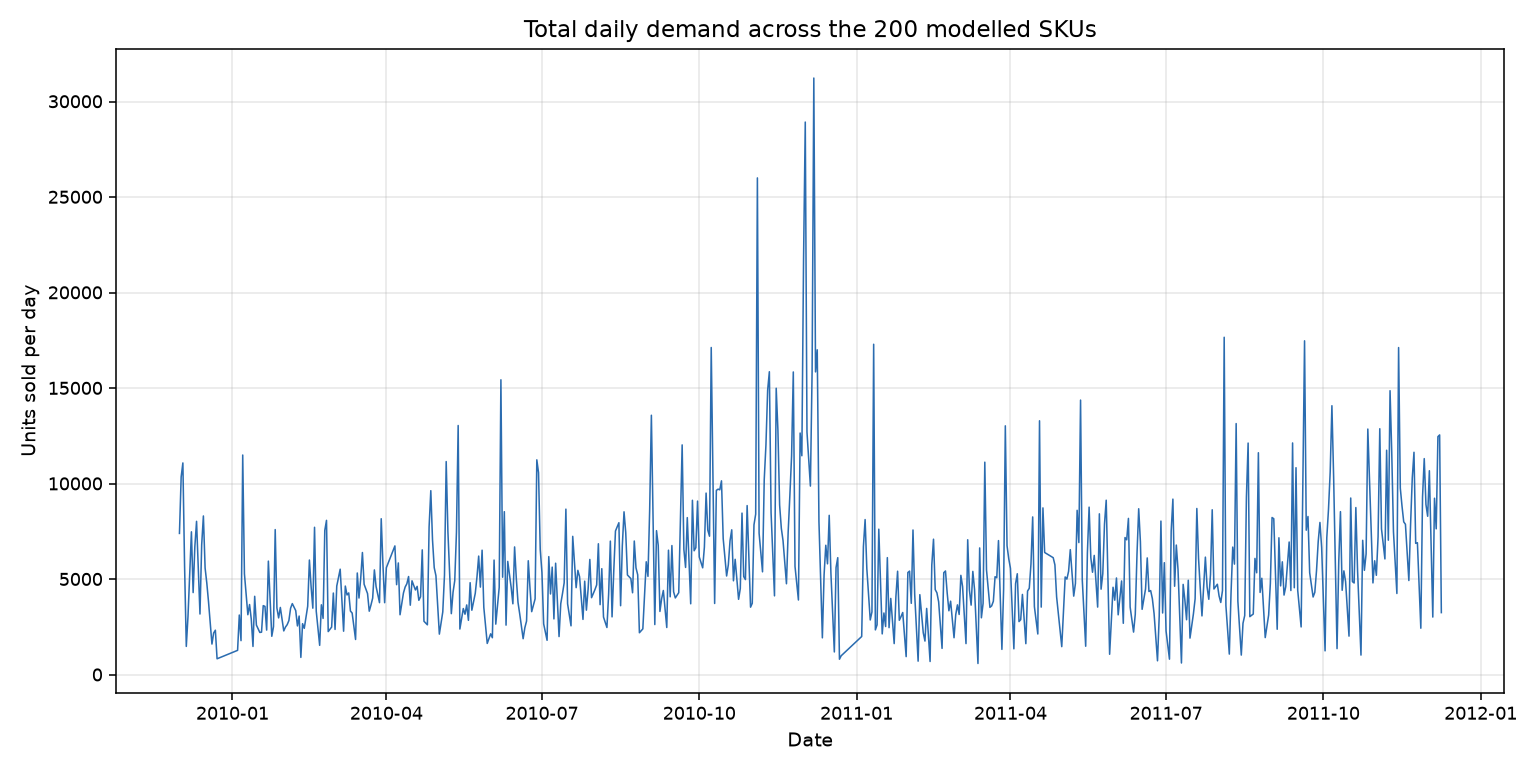

### 02_weekly_trend

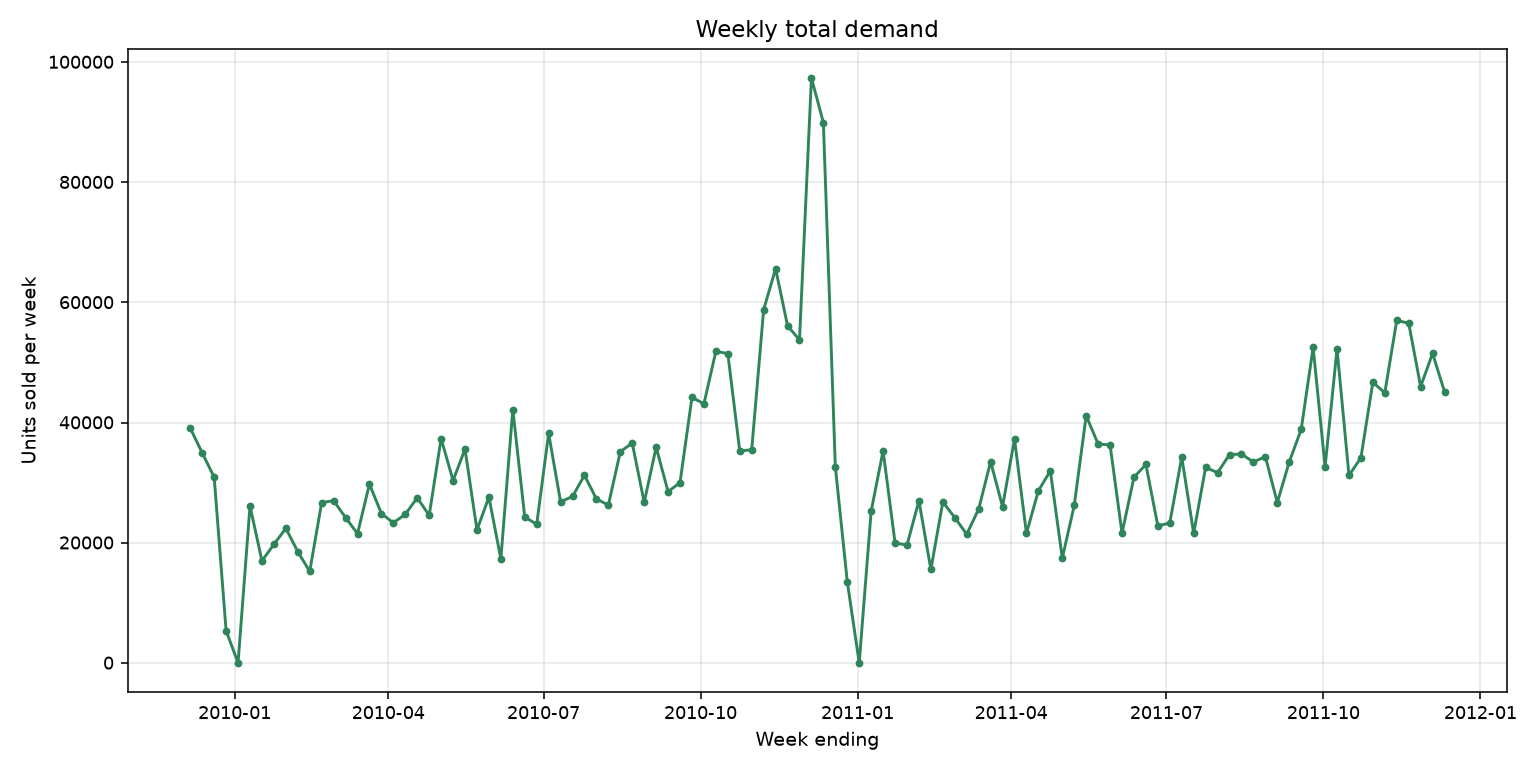

### 03_monthly_trend

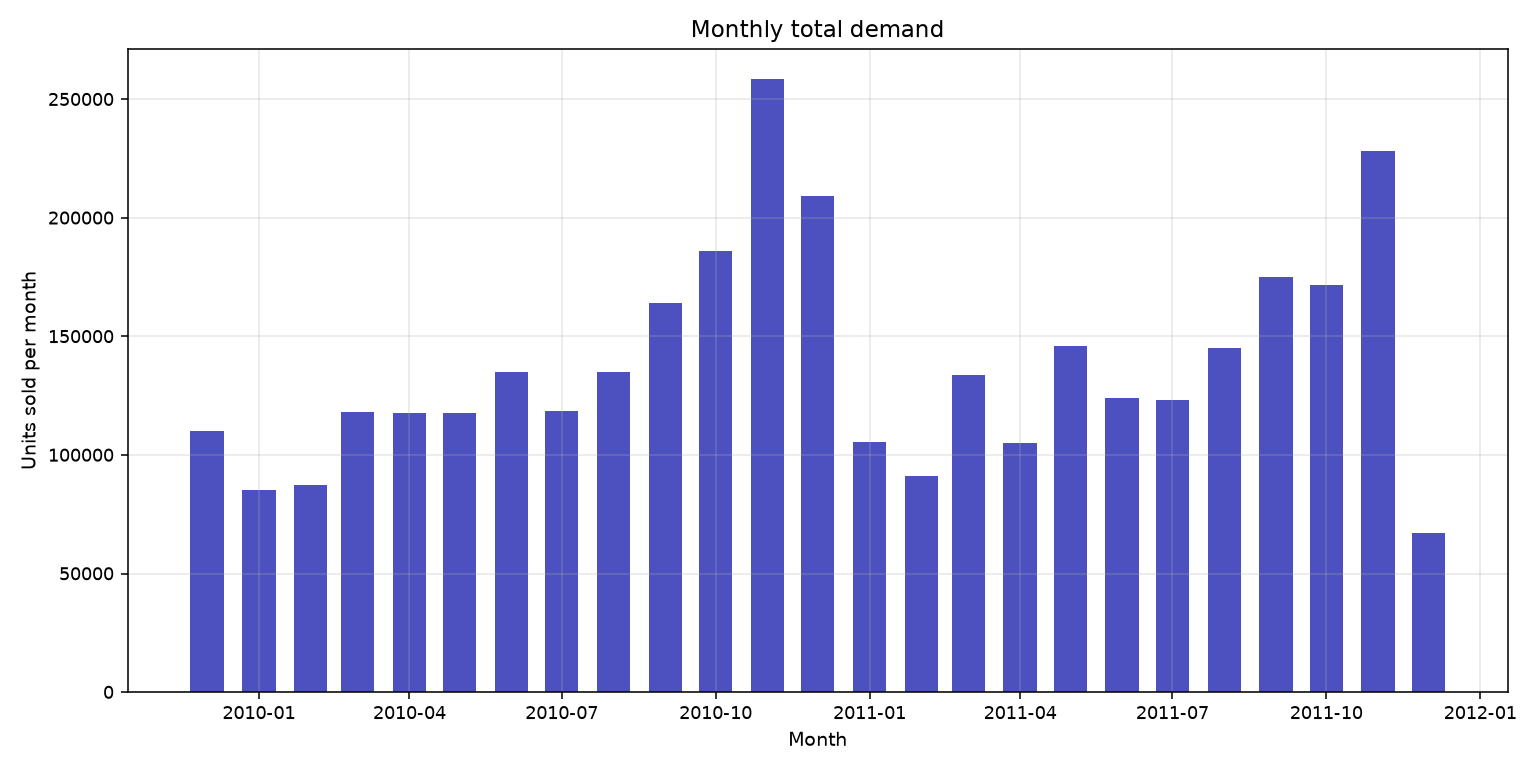

### 04_demand_distribution

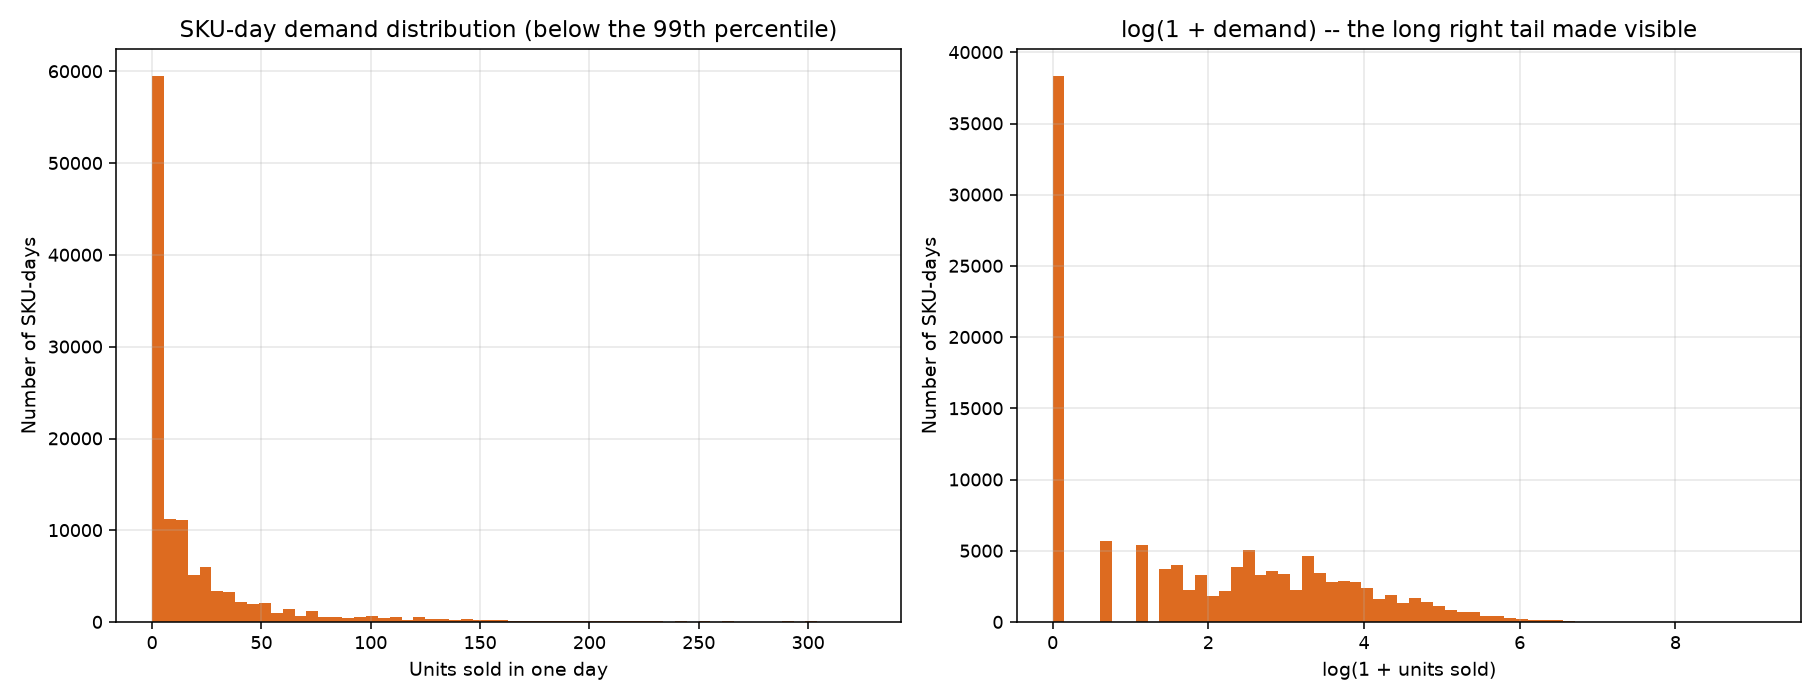

### 05_outliers_boxplot

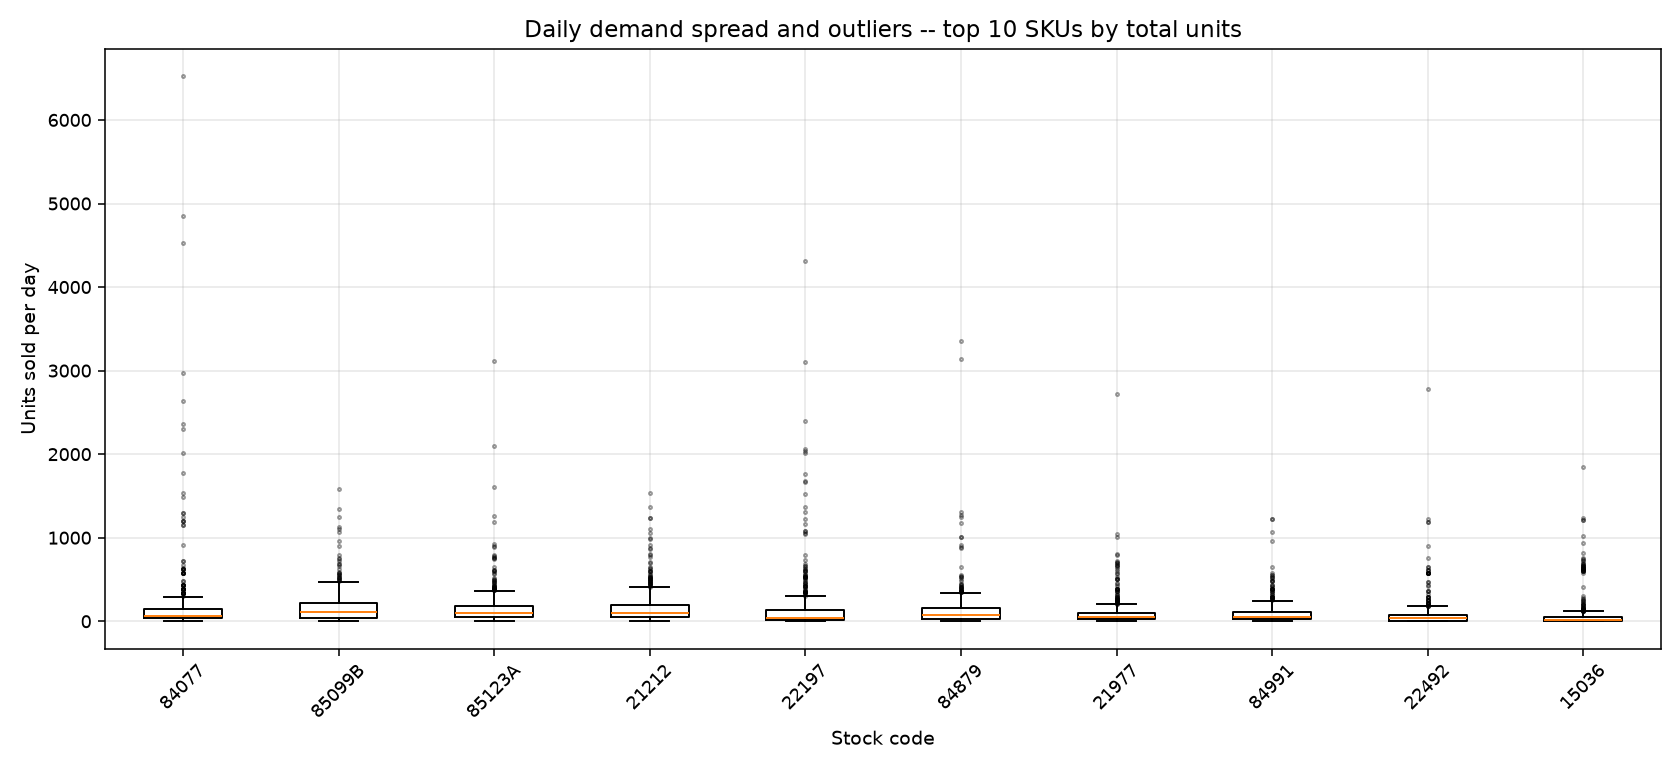

### 06_top_skus_revenue

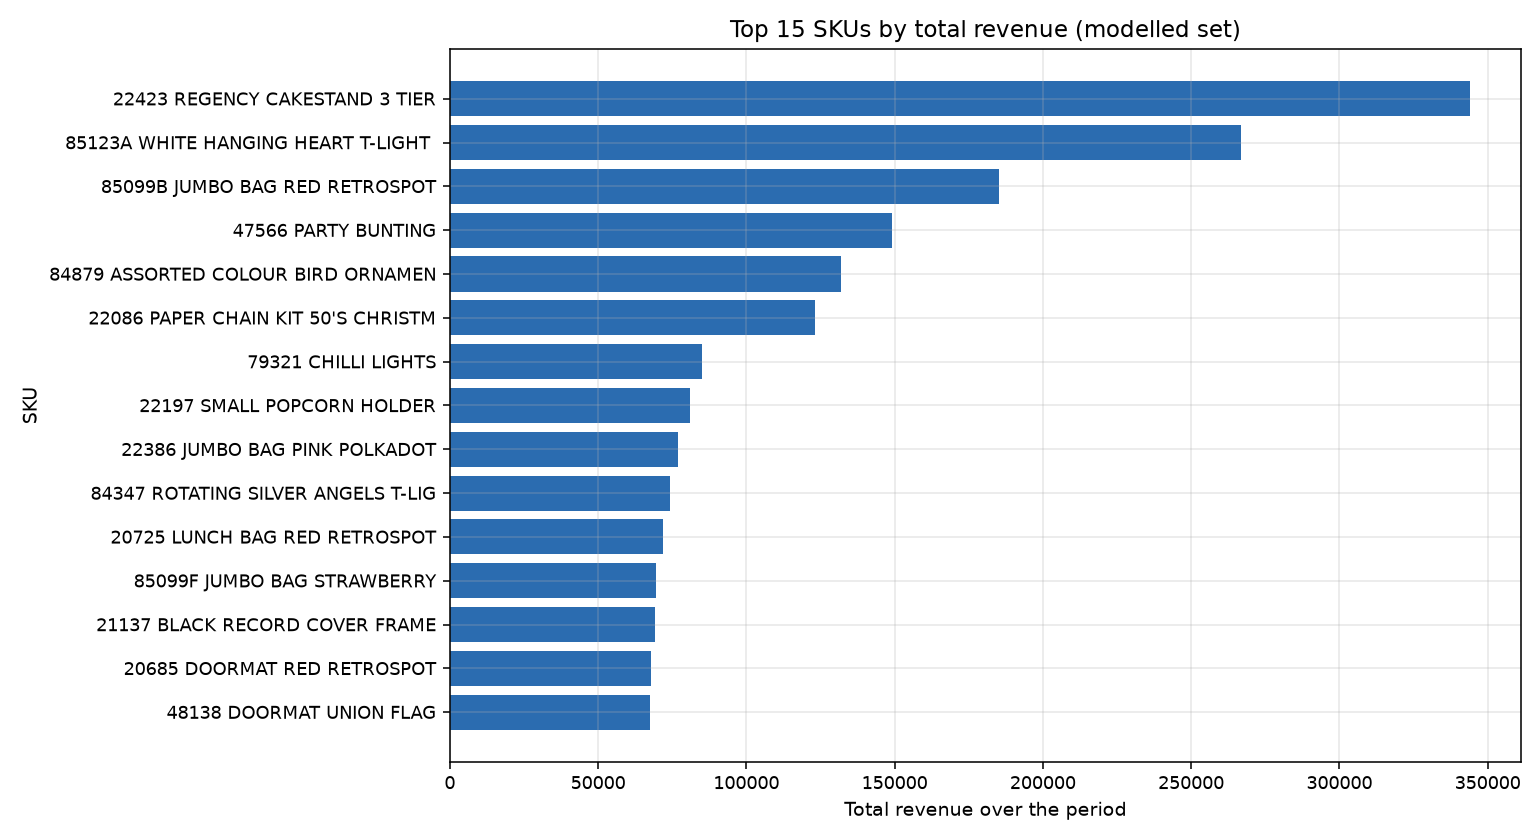

### 07_pareto_revenue

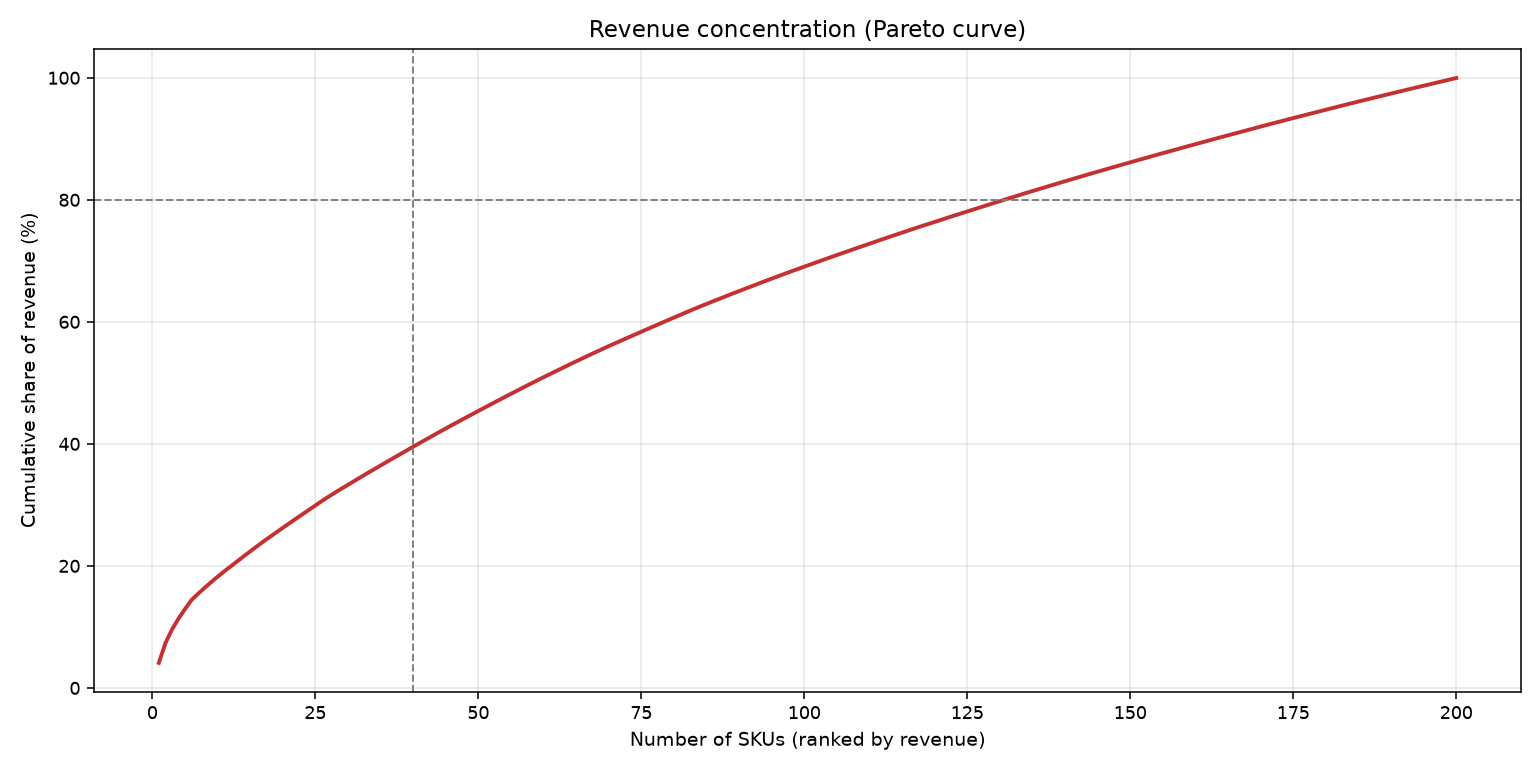

### 08_day_of_week

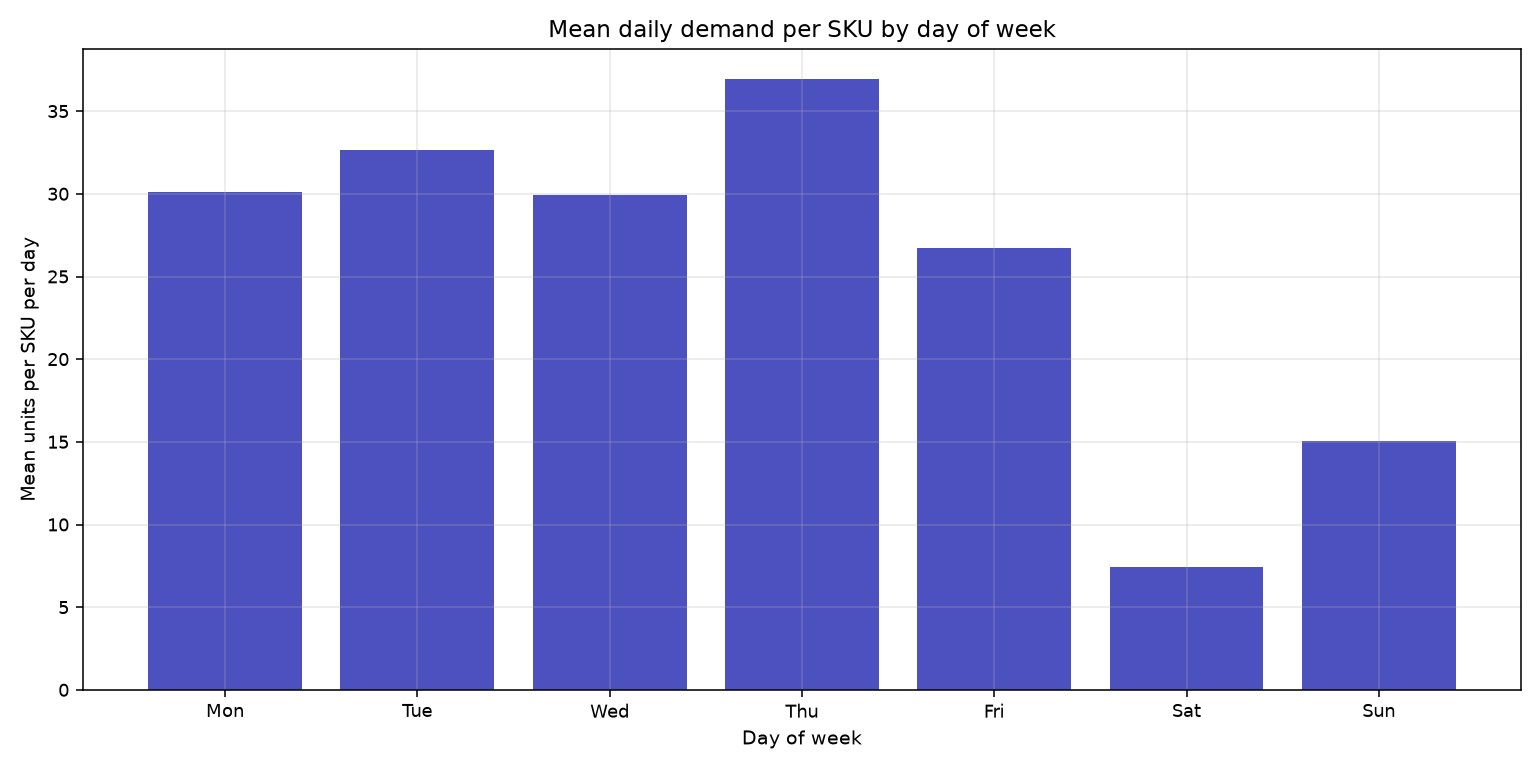

### 09_correlation_heatmap

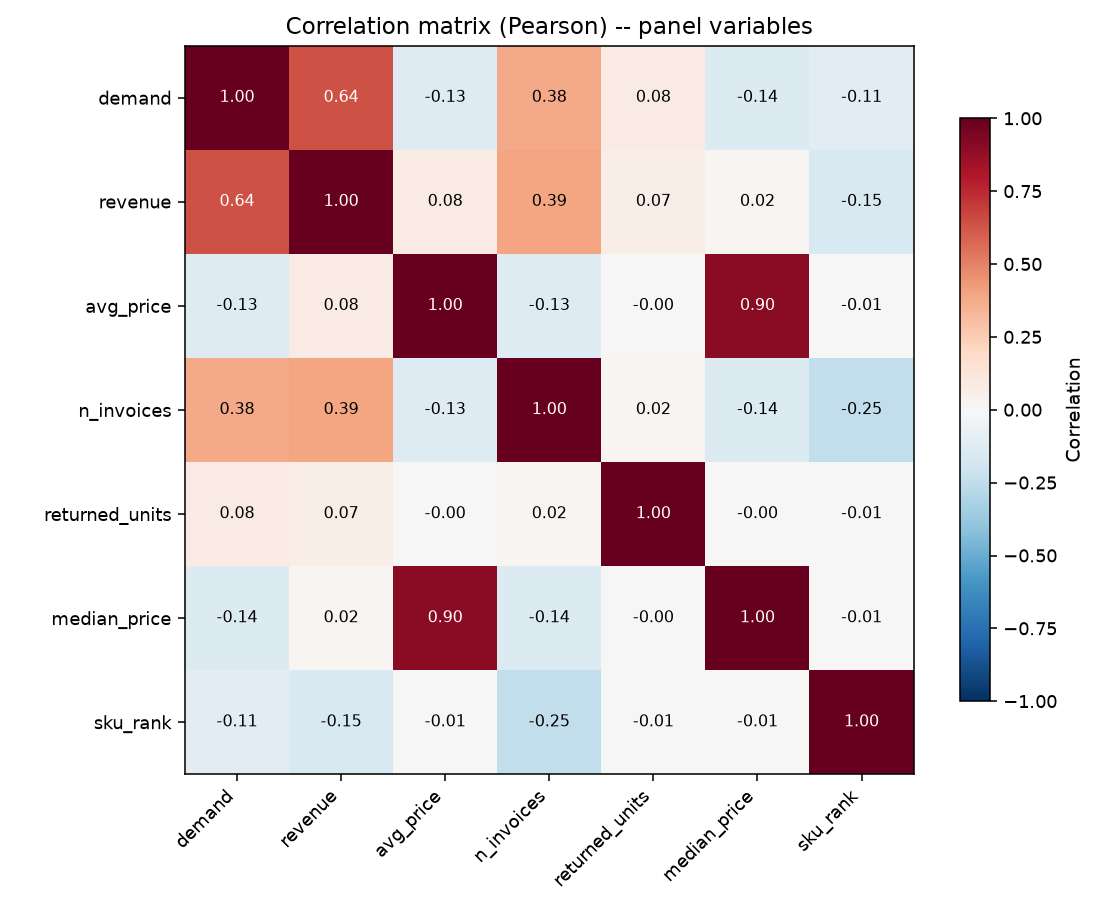

### 10_invoices_vs_demand

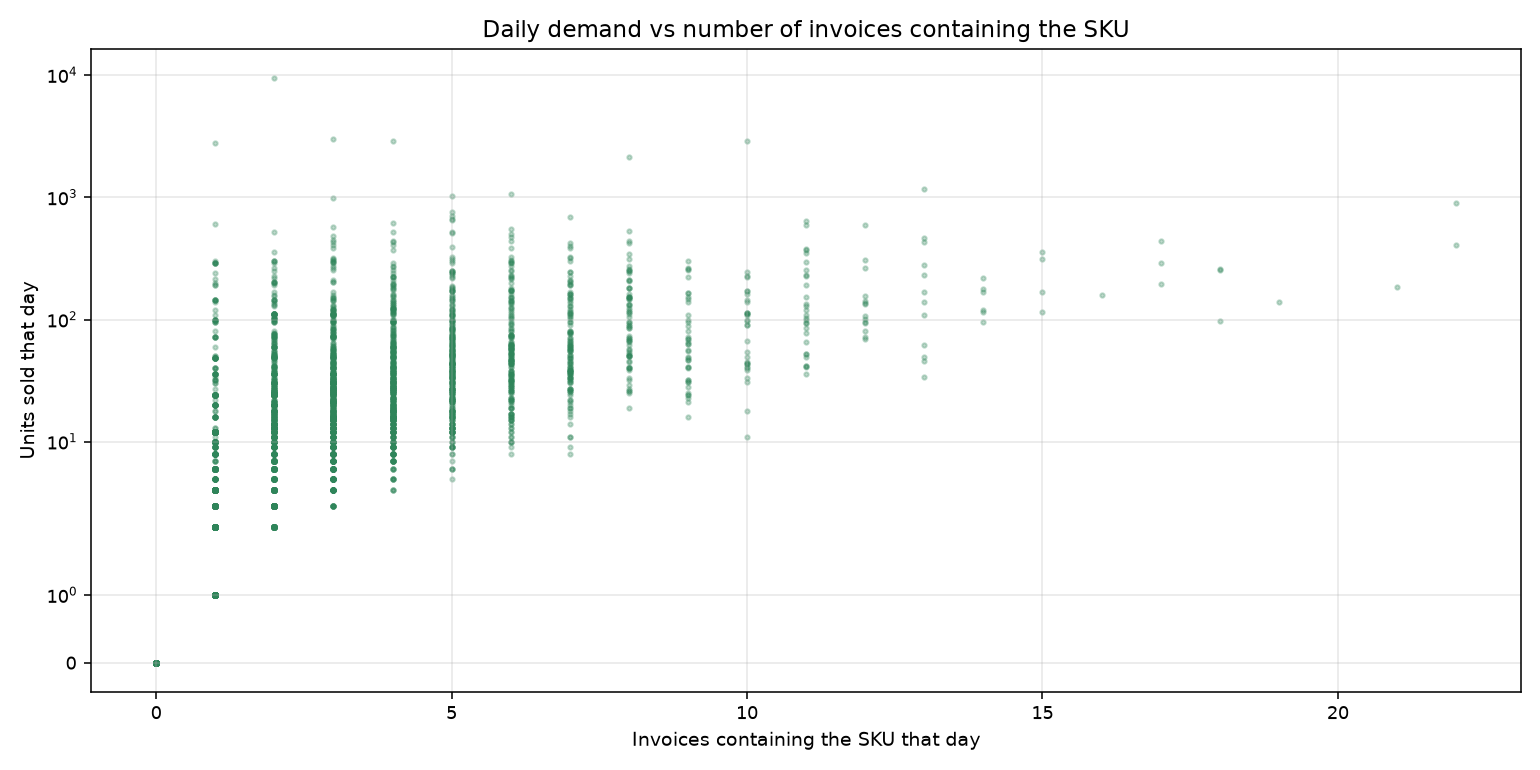

### 11_price_vs_demand

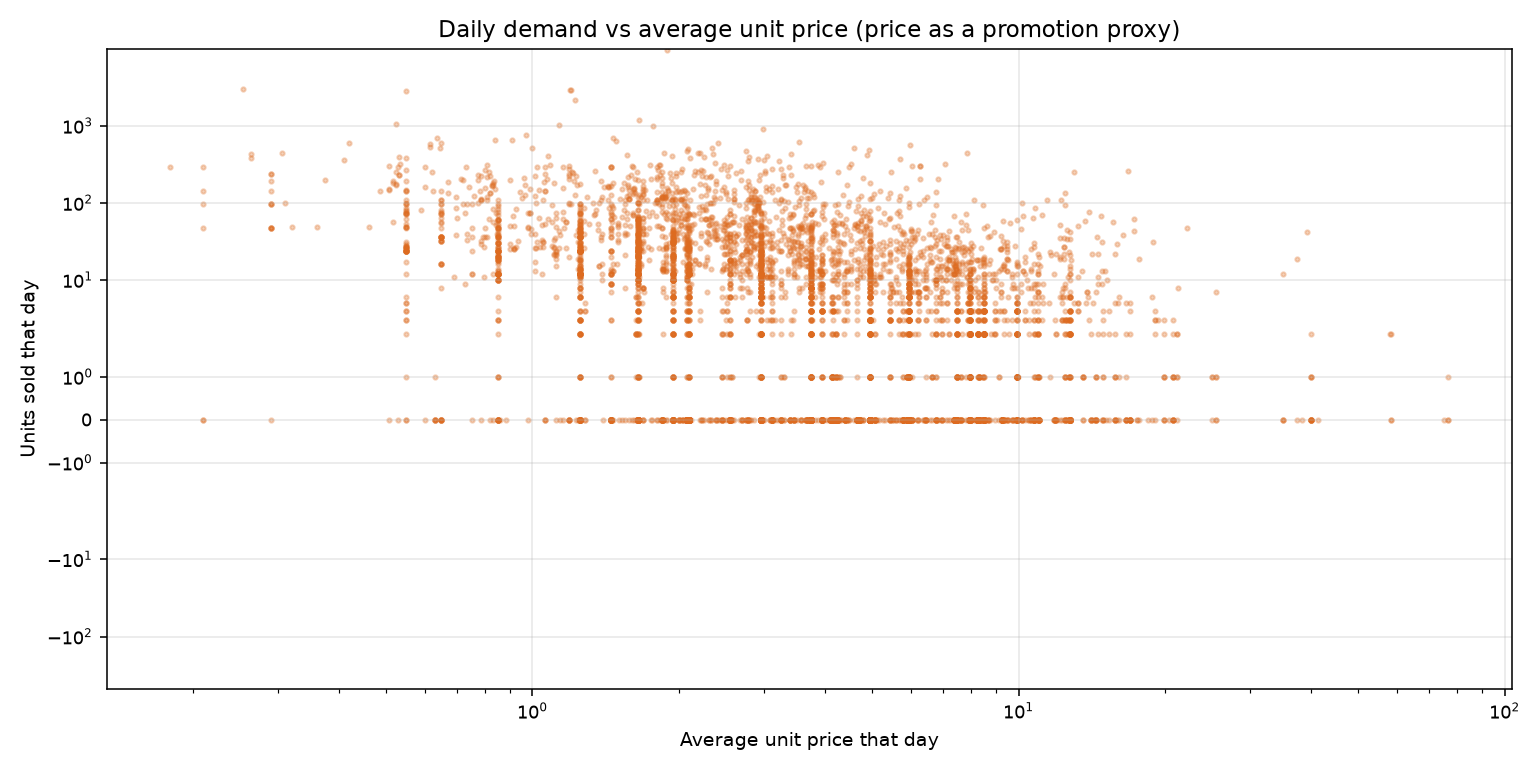

### 12_zero_demand

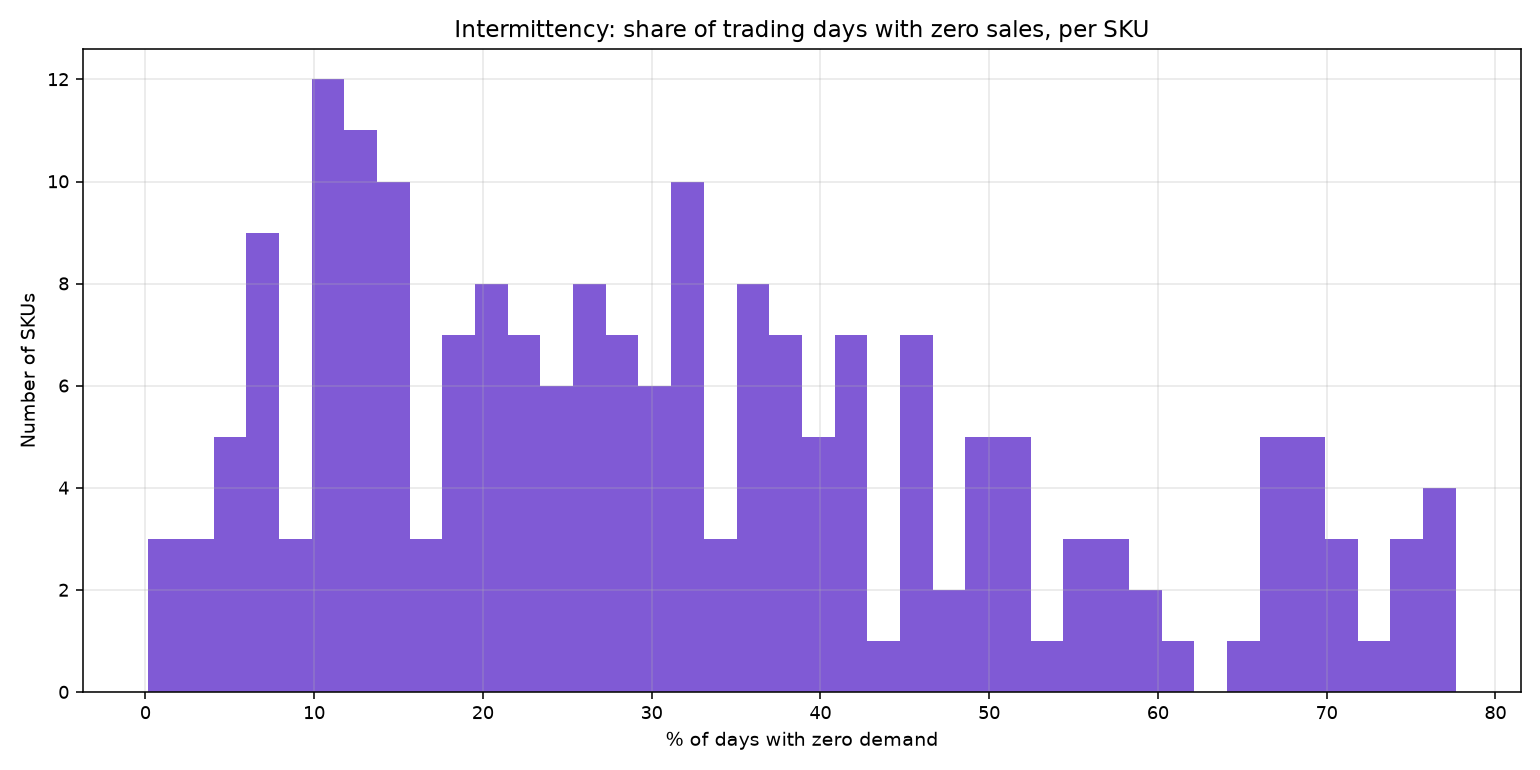

### 13_rolling_mean

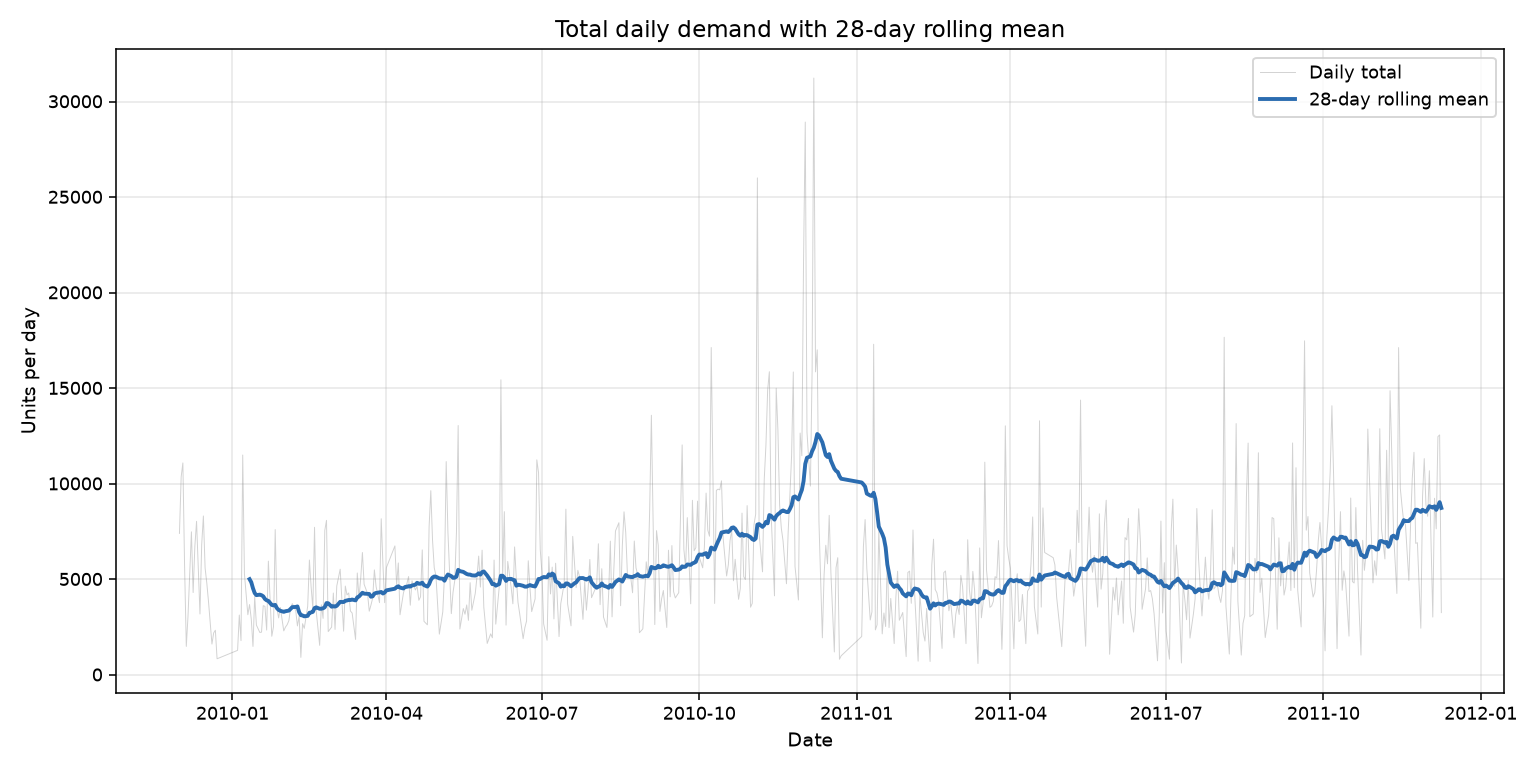

### 14_rolling_std

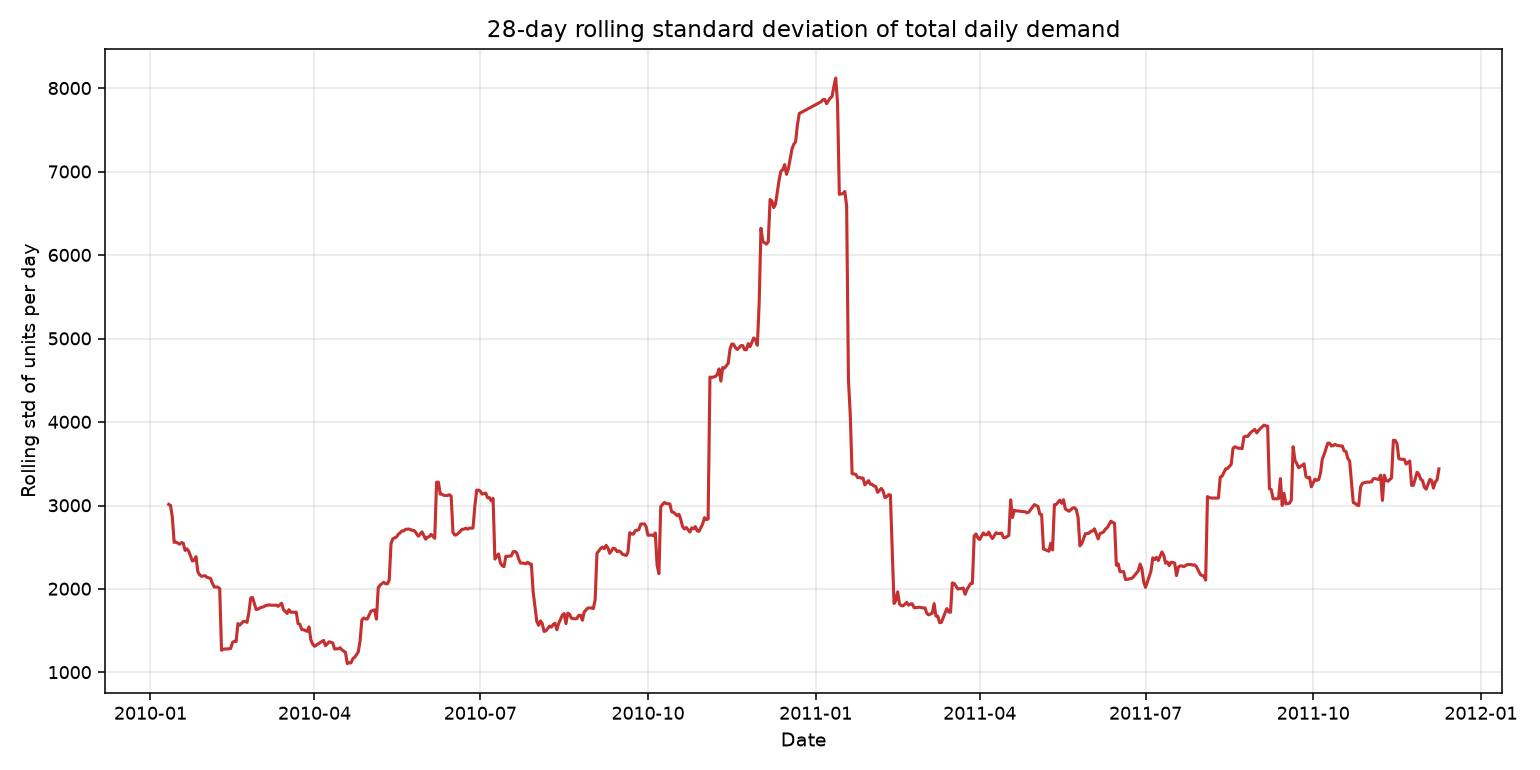

### 15_target_quantiles

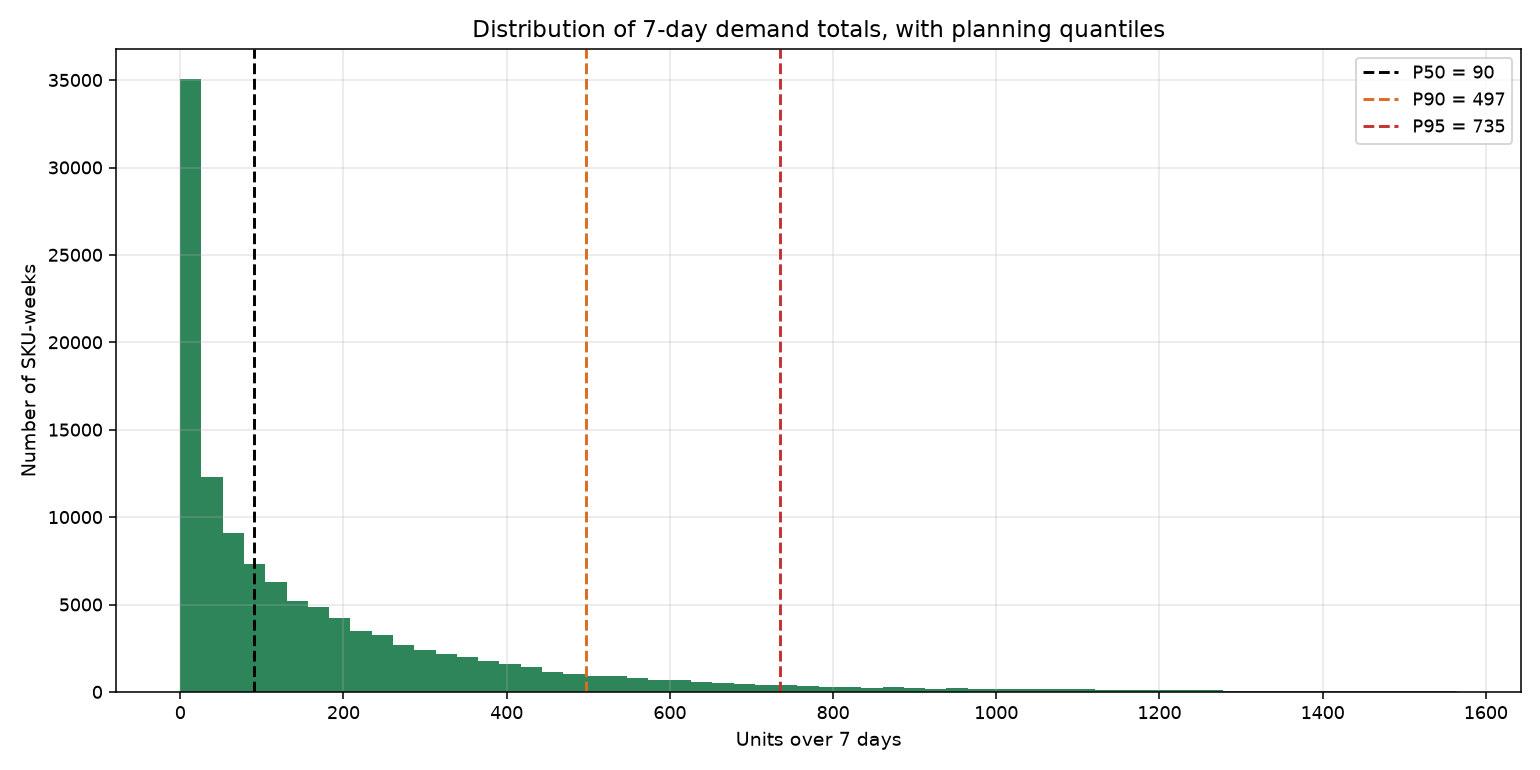

### 16_seasonal_decomposition

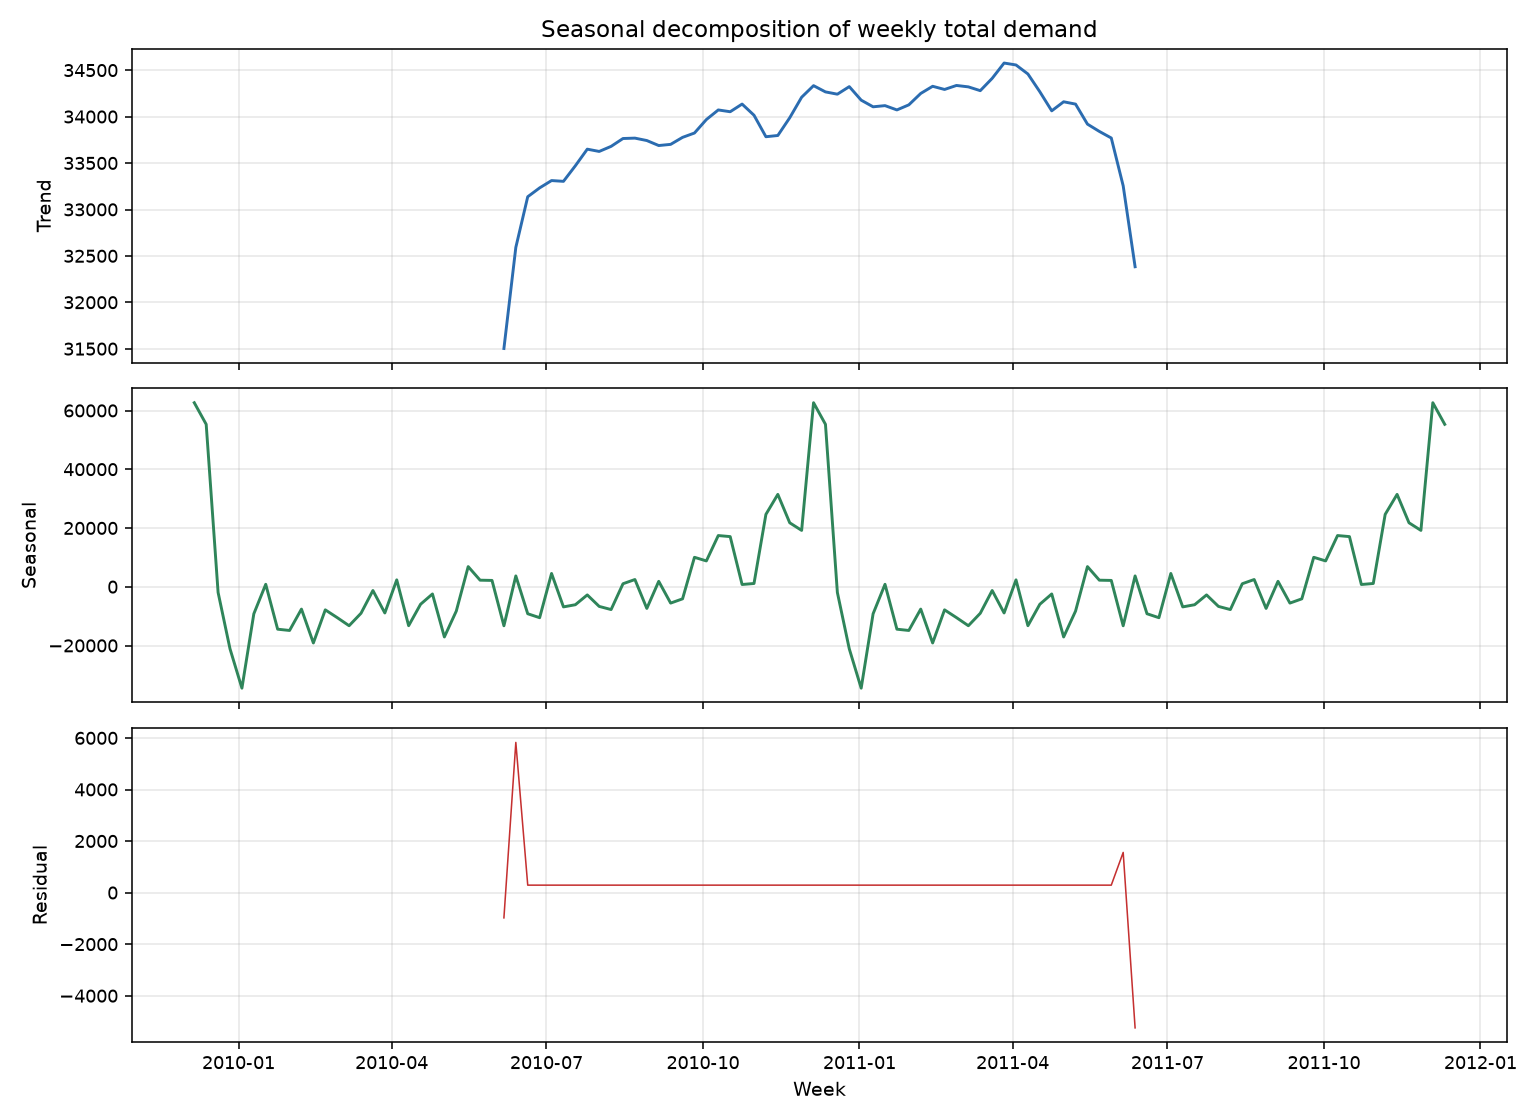

In [4]:
from IPython.display import Image, display, Markdown
for name in sorted(find['figures']):
    display(Markdown(f'### {name}'))
    display(Image(filename=str(ROOT / find['figures'][name])))

## Trading calendar

In [5]:
pd.Series(find['trading_calendar']['mean_demand_by_weekday'],
          name='mean units per SKU per day').to_frame()

,mean units per SKU per day
Mon,30.146011
Tue,32.643702
Wed,29.916923
Thu,36.936311
Fri,26.755051
Sat,7.415000
Sun,15.043081


The written interpretation of every figure — observation, interpretation and business implication — is in [`docs/eda_insights.md`](../docs/eda_insights.md).